# RQ1 – Lending Landscape (PySpark)

Reproduces RQ1.1–RQ1.4 from `RQ1_Pandas.ipynb` on S0 from `clean_spark/S0_all`. Spark performs all application-level computations; only small aggregated tables are collected for display and plotting. Percentiles use `percentile_approx` (accuracy 100,000).

- **Outputs:** `rq1_spark/` (CSV tables, PNG figures)
- The comparison with the Pandas results is in the last section of `RQ1_Pandas.ipynb`.

## Setup and Data Loading

In [1]:
!pip install pyspark -q
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p /content/clean_spark
!cp -rn /content/drive/MyDrive/hmda/clean_spark/S0_all /content/clean_spark/

import os, sys, time
import pandas as pd
import matplotlib.pyplot as plt
from itertools import chain
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder.appName("HMDA2024_PySpark")
         .config("spark.driver.memory", "8g")
         .config("spark.sql.shuffle.partitions", "64")
         .getOrCreate())
spark.catalog.clearCache()          # release cached data from earlier sections (if any)

BASE = "/content/drive/MyDrive/hmda/"
OUT  = BASE + "rq1_spark/"
os.makedirs(OUT, exist_ok=True)
sys.path.insert(0, BASE)
import rules

ACTION = {"1": "Originated", "2": "Approved not accepted", "3": "Denied",
          "4": "Withdrawn", "5": "Incomplete", "6": "Purchased",
          "7": "Preapproval denied", "8": "Preapproval approved not accepted"}
LOAN_TYPE = {"1": "Conventional", "2": "FHA", "3": "VA", "4": "USDA (RHS/FSA)"}
PURPOSE = {"1": "Home purchase", "2": "Home improvement", "31": "Refinancing",
           "32": "Cash-out refinancing", "4": "Other purpose", "5": "Not applicable"}

def label(col, d):
    """Label HMDA codes (equivalent to Pandas .map())."""
    return F.create_map(*[F.lit(x) for x in chain(*d.items())])[F.col(col)]

COLS = ["action_taken", "loan_amount", "income", "loan_type", "loan_purpose",
        "denied_flag", "log_income", "log_loan_amount"]

t0 = time.time()
s0 = (spark.read.parquet("/content/clean_spark/S0_all").select(*COLS)
        .withColumn("action_label",  label("action_taken", ACTION))
        .withColumn("type_label",    label("loan_type", LOAN_TYPE))
        .withColumn("purpose_label", label("loan_purpose", PURPOSE))
        .cache())
total = s0.count()
print(f"Load + cache S0: {time.time()-t0:.1f}s | {total:,} rows")

Mounted at /content/drive
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
Load + cache S0: 61.3s | 12,259,199 rows


## RQ1.1 — Application Outcomes

,outcome,count,share_%
0,Originated,6197085,50.55
1,Denied,2103462,17.16
2,Withdrawn,1538273,12.55
3,Purchased,1276504,10.41
4,Incomplete,581940,4.75
5,Approved not accepted,361232,2.95
6,Preapproval approved not accepted,153391,1.25
7,Preapproval denied,47312,0.39


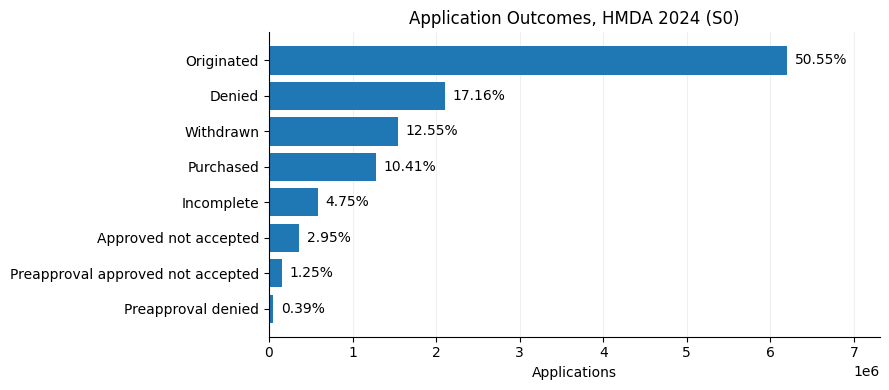

In [2]:
outcome = (s0.groupBy("action_label").count()
             .withColumnRenamed("action_label", "outcome")
             .orderBy(F.desc("count")).toPandas())
outcome["share_%"] = (outcome["count"] / total * 100).round(2)
outcome.to_csv(OUT + "R1_outcomes.csv", index=False)
display(outcome)


o = outcome.sort_values("count")

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(o["outcome"], o["count"])

# Add space on the right for percentage labels
max_count = o["count"].max()
ax.set_xlim(0, max_count * 1.18)

# Add percentage labels
for bar, share in zip(bars, o["share_%"]):
    ax.text(
        bar.get_width() + max_count * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{share:.2f}%",
        va="center",
        ha="left",
        fontsize=10
    )

ax.set_xlabel("Applications")
ax.set_ylabel("")
ax.set_title("Application Outcomes, HMDA 2024 (S0)")

# Cleaner formatting
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    OUT + "R1_outcomes.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## RQ1.2 — Baseline Denial Rate by Loan Type and Loan Purpose

Baseline denial rate = denied / (originated + denied) = 25.34%

=== By loan type ===


,applications,denial_rate,share_of_S1_%
type_label,,,
Conventional,6601706,26.71,79.53
FHA,1072243,22.42,12.92
VA,584996,16.10,7.05
USDA (RHS/FSA),41602,12.71,0.50



=== By loan purpose ===


,applications,denial_rate,share_of_S1_%
purpose_label,,,
Home purchase,4158055,15.01,50.09
Cash-out refinancing,1165962,33.99,14.05
Other purpose,1078317,44.41,12.99
Home improvement,972499,39.11,11.72
Refinancing,922327,24.20,11.11
Not applicable,3387,26.16,0.04


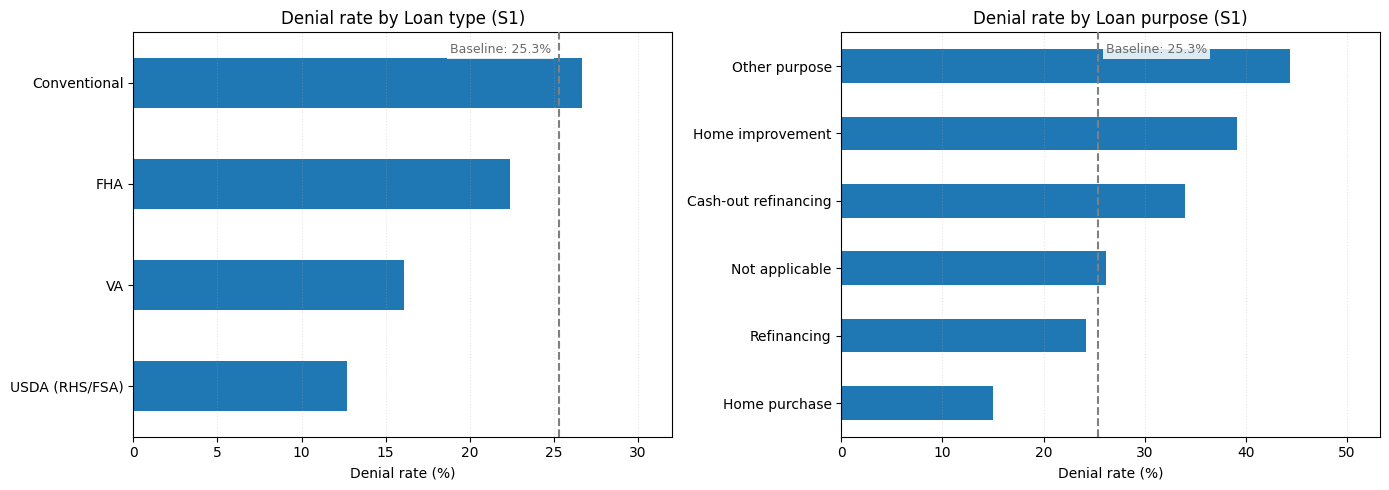

In [3]:
s1 = s0.filter(F.col("action_taken").isin(rules.S1_CODES))
n_s1 = s1.count()

base_rate = s1.agg(F.mean("denied_flag")).first()[0] * 100
print(f"Baseline denial rate = denied / (originated + denied) = {base_rate:.2f}%")


def rate_by(col):
    t = (
        s1.groupBy(col)
        .agg(
            F.count("*").alias("applications"),
            F.mean("denied_flag").alias("denial_rate")
        )
        .toPandas()
    )

    t["denial_rate"] = (t["denial_rate"] * 100).round(2)
    t["share_of_S1_%"] = (t["applications"] / n_s1 * 100).round(2)

    return t.sort_values("applications", ascending=False).set_index(col)


rate_type = rate_by("type_label")
rate_purpose = rate_by("purpose_label")

rate_type.to_csv(OUT + "R2_denial_by_loan_type.csv")
rate_purpose.to_csv(OUT + "R2_denial_by_purpose.csv")

print("\n=== By loan type ===")
display(rate_type)

print("\n=== By loan purpose ===")
display(rate_purpose)


# Plot denial rates with baseline reference
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, t, title in [
    (axes[0], rate_type, "Loan type"),
    (axes[1], rate_purpose, "Loan purpose")
]:
    rates = t["denial_rate"].sort_values()

    rates.plot.barh(ax=ax)

    # Set x-axis limits with sufficient space for labels
    x_max = max(rates.max(), base_rate) * 1.20
    ax.set_xlim(0, x_max)

    # Baseline reference line
    ax.axvline(
        base_rate,
        linestyle="--",
        color="grey",
        linewidth=1.5,
        zorder=3
    )

    # Position baseline label inside the plot
    label_on_right = base_rate < x_max * 0.72

    ax.annotate(
        f"Baseline: {base_rate:.1f}%",
        xy=(base_rate, 0.98),
        xycoords=("data", "axes fraction"),
        xytext=(6 if label_on_right else -6, -2),
        textcoords="offset points",
        ha="left" if label_on_right else "right",
        va="top",
        fontsize=9,
        color="dimgray",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.85,
            pad=2
        )
    )

    ax.set_xlabel("Denial rate (%)")
    ax.set_ylabel("")
    ax.set_title(f"Denial rate by {title} (S1)")
    ax.grid(axis="x", linestyle=":", alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUT + "R2_denial_rates.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## RQ1.3 — Loan Amount and Income Distributions

,variable,unit,n,p1,Q1,median,Q3,IQR,p99,mean
0,loan_amount,USD,12259199,15000.0,105000.0,225000.0,375000.0,270000.0,1445000.0,315308.7
1,income,USD thousands,10313511,20.0,69.0,105.0,166.0,97.0,843.0,326.1


,loan_amount,income
type_label,,
Conventional,185000.0,112.0
FHA,275000.0,85.0
USDA (RHS/FSA),175000.0,73.0
VA,335000.0,102.0


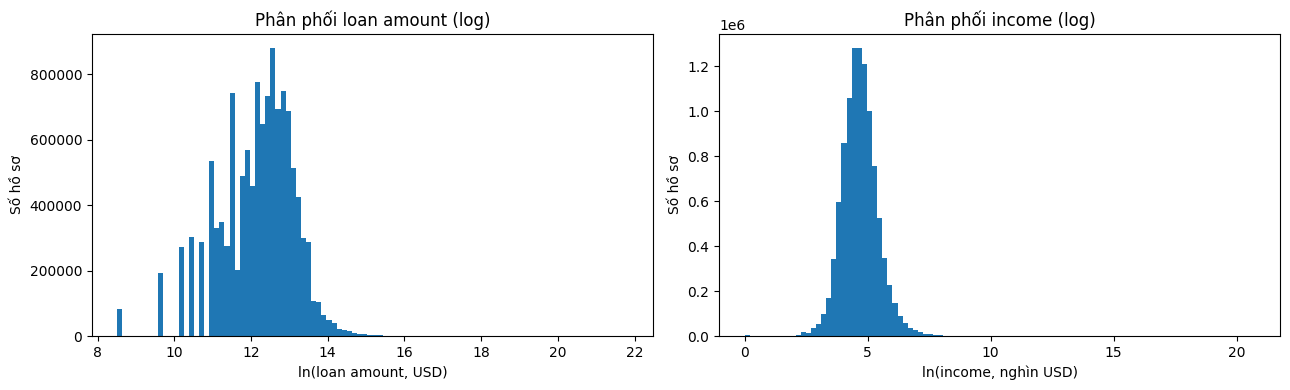

In [ ]:
QS = [0.01, 0.25, 0.5, 0.75, 0.99]

def dist_stats(col, unit):
    r = s0.agg(F.count(col).alias("n"), F.mean(col).alias("mean"),
               F.percentile_approx(col, QS, 100000).alias("q")).first()
    q = r["q"]
    return {"variable": col, "unit": unit, "n": r["n"], "p1": q[0], "Q1": q[1],
            "median": q[2], "Q3": q[3], "IQR": q[3] - q[1], "p99": q[4], "mean": r["mean"]}

dist = pd.DataFrame([dist_stats("loan_amount", "USD"),
                     dist_stats("income", "USD thousands")]).round(1)
dist.to_csv(OUT + "R3_distribution_stats.csv", index=False)
display(dist)

# Median by loan type
med_type = (s0.groupBy("type_label")
              .agg(F.percentile_approx("loan_amount", 0.5, 100000).alias("loan_amount"),
                   F.percentile_approx("income", 0.5, 100000).alias("income"))
              .toPandas().set_index("type_label").sort_index())
med_type.to_csv(OUT + "R3_median_by_loan_type.csv")
display(med_type)

# Histogram: Spark bins the data into 100 intervals and counts them; only the count table is collected for plotting
def spark_hist(col, bins=100):
    mn, mx = s0.agg(F.min(col), F.max(col)).first()
    w = (mx - mn) / bins
    h = (s0.where(F.col(col).isNotNull())
           .select(F.least(F.floor((F.col(col) - mn) / w), F.lit(bins - 1)).alias("b"))
           .groupBy("b").count().toPandas().sort_values("b"))
    return mn + h["b"] * w, h["count"], w

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, title, xl in [(axes[0], "log_loan_amount", "Loan amount distribution (log)", "ln(loan amount, USD)"),
                           (axes[1], "log_income", "Income distribution (log)", "ln(income, USD thousands)")]:
    x, y, w = spark_hist(col)
    ax.bar(x, y, width=w, align="edge")
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel("Applications")
plt.tight_layout(); plt.savefig(OUT + "R3_distributions_log.png", dpi=150); plt.show()

## RQ1.4 — Loan Type × Loan Purpose Mix

,Conventional,FHA,USDA (RHS/FSA),VA,Total
purpose_label,,,,,
Cash-out refinancing,9.06,3.32,0.00,1.79,14.17
Home improvement,9.75,0.08,0.00,0.01,9.84
Home purchase,38.16,10.07,0.61,4.83,53.67
Not applicable,0.06,0.09,0.00,0.01,0.16
Other purpose,11.15,0.23,0.00,0.02,11.40
Refinancing,7.61,1.50,0.01,1.65,10.77
Total,75.79,15.29,0.62,8.31,100.01


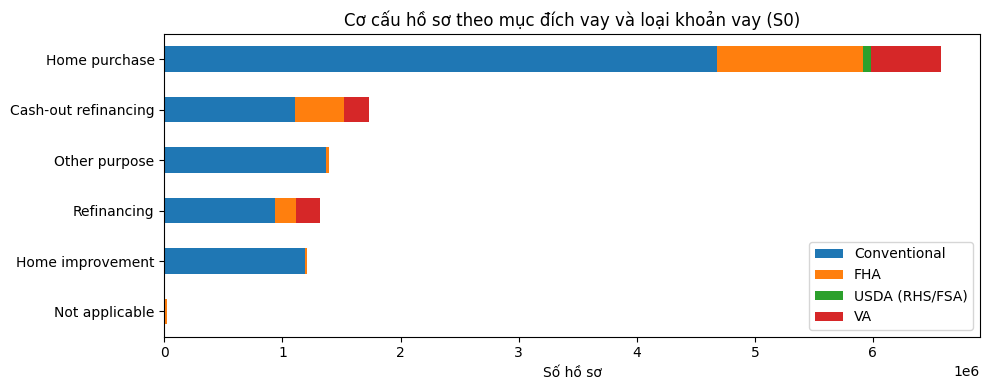

In [ ]:
ct = (s0.groupBy("purpose_label").pivot("type_label").count()
        .toPandas().set_index("purpose_label").fillna(0).sort_index())
ct = ct[sorted(ct.columns)]

mix = (ct / total * 100).round(2)
mix["Total"] = mix.sum(axis=1)
mix.loc["Total"] = mix.sum()
mix.to_csv(OUT + "R4_mix_purpose_x_type.csv")
display(mix)

ax = ct.loc[ct.sum(axis=1).sort_values().index].plot.barh(stacked=True, figsize=(10, 4))
ax.set_xlabel("Applications"); ax.set_ylabel("")
ax.set_title("Applications by Loan Purpose and Loan Type (S0)")
plt.tight_layout(); plt.savefig(OUT + "R4_mix.png", dpi=150); plt.show()

## Summary

In [ ]:
print(f"Total applications (S0): {total:,}")
print(f"Baseline denial rate (S1): {base_rate:.2f}%")
print("\nTop 3 application outcomes:")
print(outcome.head(3).to_string(index=False))
print(f"\nMedian loan amount: ${dist.loc[0,'median']:,.0f} | IQR: ${dist.loc[0,'IQR']:,.0f}")
print(f"Median income: ${dist.loc[1,'median']*1000:,.0f}/year | IQR: ${dist.loc[1,'IQR']*1000:,.0f}")
print("\nHighest denial rates by loan purpose:")
print(rate_purpose["denial_rate"].sort_values(ascending=False).head(3).to_string())
!ls -lh {OUT}

Total applications (S0): 12,259,199
Baseline denial rate (S1): 25.34%

Top 3 application outcomes:
   outcome   count  share_%
Originated 6197085    50.55
    Denied 2103462    17.16
 Withdrawn 1538273    12.55

Median loan amount: $225,000 | IQR: $270,000
Median income: $105,000/year | IQR: $97,000

Highest denial rates by loan purpose:
purpose_label
Other purpose           44.41
Home improvement        39.11
Cash-out refinancing    33.99
total 218K
-rw------- 1 root root 249 Nov 15 09:03 R1_outcomes.csv
-rw------- 1 root root 61K Nov 15 09:03 R1_outcomes.png
-rw------- 1 root root 158 Nov 15 09:03 R2_denial_by_loan_type.csv
-rw------- 1 root root 259 Nov 15 09:03 R2_denial_by_purpose.csv
-rw------- 1 root root 57K Nov 15 09:03 R2_denial_rates.png
-rw------- 1 root root 47K Nov 15 09:05 R3_distributions_log.png
-rw------- 1 root root 199 Nov 15 09:04 R3_distribution_stats.csv
-rw------- 1 root root 123 Nov 15 09:05 R3_median_by_loan_type.csv
-rw------- 1 root root 51K Nov 15 09:06 R4_